# Museum Artwork Guide — Final Project (m1–m4)

This notebook builds and evaluates the neural-network parts of the museum guide using the local `data/wikiart_subset` dataset.

**Project checkpoints**
- **m1:** Dense feed-forward baseline in PyTorch.
- **m2:** Training/validation curves and error diagnosis.
- **m3:** ImageNet-pretrained ResNet-18, then fine-tuning; compare with the dense baseline.
- **m4:** Text-to-artwork retrieval using TF–IDF (classical) and sentence embeddings (neural), then compare evidence and practical trade-offs.

## 0. Setup

If an import fails, install the missing package in the same Python environment used by this notebook. The core image models use PyTorch/torchvision; m4's sentence-embedding section optionally uses `sentence-transformers`.

In [85]:
from pathlib import Path
import os, random, json, time, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("data/wikiart_subset")
OUTPUT_DIR = Path("outputs_official")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Dataset folder exists:", DATA_DIR.exists(), "|", DATA_DIR.resolve())

Device: cpu
Dataset folder exists: True | /Users/tranngocminhhoang/Documents/Netral Network Project/Project-HSM/data/wikiart_subset


## 1. Inspect the dataset and metadata

In [86]:
assert DATA_DIR.exists(), f"Could not find {DATA_DIR.resolve()}. Run the notebook from your project root."
metadata_path = DATA_DIR / "metadata.csv"
metadata = pd.read_csv(metadata_path) if metadata_path.exists() else pd.DataFrame()

print("Metadata shape:", metadata.shape)
display(metadata.head())
print("\nMetadata columns:", metadata.columns.tolist())

Metadata shape: (1500, 11)


,path,label,label_idx,id,style,genre,artist,shard,row,orig_width,orig_height
0,Baroque/s54_r0037.jpg,Baroque,0,s54_r0037,Baroque,landscape,peter-paul-rubens,54,37,2442,1382
1,Baroque/s54_r0159.jpg,Baroque,0,s54_r0159,Baroque,landscape,Unknown Artist,54,159,1682,1382
2,Baroque/s54_r0182.jpg,Baroque,0,s54_r0182,Baroque,landscape,Unknown Artist,54,182,2234,1382
3,Baroque/s54_r0221.jpg,Baroque,0,s54_r0221,Baroque,landscape,peter-paul-rubens,54,221,1821,1382
4,Baroque/s54_r0236.jpg,Baroque,0,s54_r0236,Baroque,still_life,Unknown Artist,54,236,2008,1382



Metadata columns: ['path', 'label', 'label_idx', 'id', 'style', 'genre', 'artist', 'shard', 'row', 'orig_width', 'orig_height']


Number of images: 1500
Classes: ['Baroque', 'Cubism', 'Impressionism', 'Pop_Art', 'Ukiyo_e']
Images per class:


,count
Baroque,300
Cubism,300
Impressionism,300
Pop_Art,300
Ukiyo_e,300


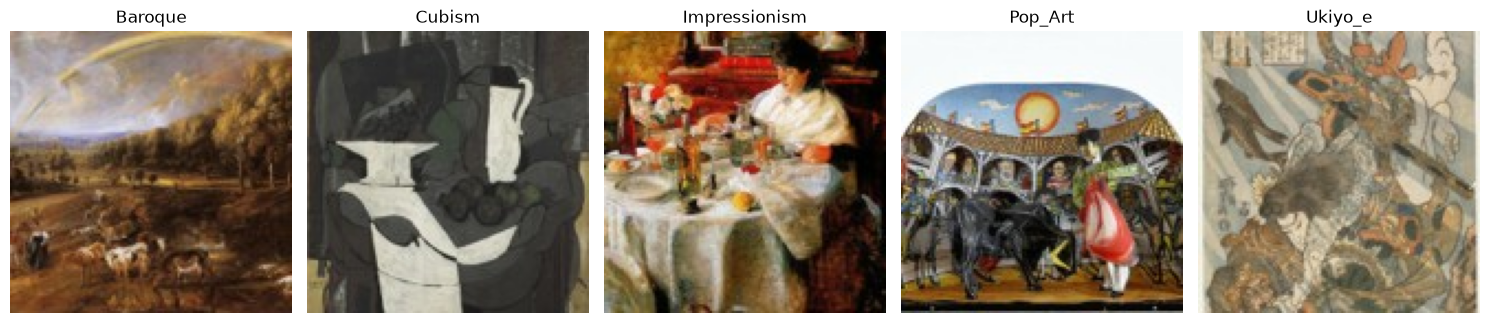

In [87]:
# ImageFolder treats each immediate subfolder as a class label.
# It ignores metadata files at the dataset root.
image_dataset = datasets.ImageFolder(DATA_DIR)
class_names = image_dataset.classes
targets = np.array(image_dataset.targets)
paths = [p for p, _ in image_dataset.samples]

print("Number of images:", len(image_dataset))
print("Classes:", class_names)
print("Images per class:")
display(pd.Series([class_names[y] for y in targets]).value_counts().reindex(class_names).rename("count").to_frame())

# Show a few sample images.
fig, axes = plt.subplots(1, min(5, len(image_dataset)), figsize=(15, 4))
axes = np.atleast_1d(axes)
for ax, idx in zip(axes, np.linspace(0, len(image_dataset)-1, min(5, len(image_dataset)), dtype=int)):
    img, label = image_dataset[idx]
    ax.imshow(img)
    ax.set_title(class_names[label])
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dataset_examples.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. Train/validation/test split

We use a stratified split so each style is represented in each split. If any class has too few examples for stratification, adjust the split or collect more images rather than silently trusting the results.

In [88]:
indices = np.arange(len(image_dataset))
train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED, stratify=targets
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=targets[temp_idx]
)
print(f"Train: {len(train_idx)} | Validation: {len(val_idx)} | Test: {len(test_idx)}")

def split_counts(idx, split_name):
    counts = pd.Series(targets[idx]).value_counts().reindex(range(len(class_names)), fill_value=0)
    return pd.DataFrame({"split": split_name, "class": class_names, "count": counts.values})

display(pd.concat([
    split_counts(train_idx, "train"),
    split_counts(val_idx, "validation"),
    split_counts(test_idx, "test")
], ignore_index=True).pivot(index="class", columns="split", values="count"))

Train: 1050 | Validation: 225 | Test: 225


split,test,train,validation
class,,,
Baroque,45,210,45
Cubism,45,210,45
Impressionism,45,210,45
Pop_Art,45,210,45
Ukiyo_e,45,210,45


## 3. Shared utilities: metrics, training loop, and checkpointing

This is an explicit PyTorch training loop: forward pass → loss → backward pass → optimizer step. Validation runs without gradient tracking. The best model is selected by validation loss and saved under `outputs/`.

In [94]:
def count_parameters(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))

def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = loss_fn(logits, y)
            if training:
                loss.backward()
                optimizer.step()

        batch_size = y.size(0)
        total_loss += loss.item() * batch_size
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += batch_size
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(y.detach().cpu().numpy())

    return {
        "loss": total_loss / max(total, 1),
        "accuracy": correct / max(total, 1),
        "preds": np.array(all_preds),
        "labels": np.array(all_labels)
    }

def fit_model(model, train_loader, val_loader, optimizer, epochs, model_path, scheduler=None):
    loss_fn = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    patience, patience_limit = 0, 5

    for epoch in range(1, epochs + 1):
        train_metrics = run_epoch(model, train_loader, loss_fn, optimizer)
        with torch.no_grad():
            val_metrics = run_epoch(model, val_loader, loss_fn, optimizer=None)

        history["train_loss"].append(train_metrics["loss"])
        history["val_loss"].append(val_metrics["loss"])
        history["train_acc"].append(train_metrics["accuracy"])
        history["val_acc"].append(val_metrics["accuracy"])

        if scheduler is not None:
            scheduler.step(val_metrics["loss"])

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, model_path)
            patience = 0
        else:
            patience += 1

        print(f"Epoch {epoch:02d}/{epochs} | "
              f"train loss {train_metrics['loss']:.4f}, acc {train_metrics['accuracy']:.3f} | "
              f"val loss {val_metrics['loss']:.4f}, acc {val_metrics['accuracy']:.3f}")

        if patience >= patience_limit:
            print(f"Early stopping: validation loss did not improve for {patience_limit} epochs.")
            break

    model.load_state_dict(best_state)
    return model, history

def plot_history(history, title, filename):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], marker="o", label="train")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(True, alpha=.3)
    axes[1].plot(epochs, history["train_acc"], marker="o", label="train")
    axes[1].plot(epochs, history["val_acc"], marker="o", label="validation")
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(True, alpha=.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

def evaluate_classifier(model, loader, name):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            logits = model(x.to(DEVICE))
            preds.extend(logits.argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    acc = accuracy_score(labels, preds)
    print(f"{name} test accuracy: {acc:.4f}")
    print(classification_report(labels, preds, labels=list(range(len(class_names))),
                                target_names=class_names, zero_division=0))
    cm = confusion_matrix(labels, preds, labels=list(range(len(class_names))))
    disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(8, 7))
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False, cmap=plt.cm.Blues)
    ax.set_title(f"{name}: test confusion matrix")
    plt.tight_layout()
    safe_name = name.lower().replace(" ", "_")
    plt.savefig(OUTPUT_DIR / f"{safe_name}_confusion_matrix.png", dpi=160, bbox_inches="tight")
    plt.show()
    return acc, np.array(labels), np.array(preds)

## 4. m1 + m2 — Dense feed-forward baseline

A dense model does not explicitly preserve image structure: we resize each image to a small square, flatten the pixels, and feed them into fully connected layers. This gives us a baseline to compare against ResNet. Small images keep the input dimension manageable.

**Important:** this model can be slow or weak on images because flattening loses spatial locality. That is a useful limitation to discuss, not something to hide.

In [90]:
DENSE_SIZE = 64
BATCH_SIZE = 32
NUM_WORKERS = 0  # safe default for notebooks and VS Code on macOS/Windows

dense_transform = transforms.Compose([
    transforms.Resize((DENSE_SIZE, DENSE_SIZE)),
    transforms.ToTensor()
])

class TransformSubset(Dataset):
    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = list(map(int, indices))
        self.transform = transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        path, label = self.base_dataset.samples[self.indices[i]]
        with Image.open(path) as im:
            im = im.convert("RGB")
            x = self.transform(im)
        return x, int(label)

dense_train_ds = TransformSubset(image_dataset, train_idx, dense_transform)
dense_val_ds = TransformSubset(image_dataset, val_idx, dense_transform)
dense_test_ds = TransformSubset(image_dataset, test_idx, dense_transform)

train_loader = DataLoader(dense_train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(dense_val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(dense_test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

class DenseArtworkNet(nn.Module):
    def __init__(self, num_classes, input_size=DENSE_SIZE):
        super().__init__()
        n_in = 3 * input_size * input_size
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_in, 512),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.net(x)

dense_model = DenseArtworkNet(len(class_names)).to(DEVICE)
print(dense_model)
print("Total parameters:", f"{count_parameters(dense_model):,}")

DenseArtworkNet(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=5, bias=True)
  )
)
Total parameters: 6,358,277


Epoch 01/20 | train loss 2.1454, acc 0.200 | val loss 1.6125, acc 0.240
Epoch 02/20 | train loss 1.6210, acc 0.198 | val loss 1.5917, acc 0.200
Epoch 03/20 | train loss 1.6044, acc 0.218 | val loss 1.5856, acc 0.236
Epoch 04/20 | train loss 1.5934, acc 0.235 | val loss 1.5799, acc 0.280
Epoch 05/20 | train loss 1.5587, acc 0.271 | val loss 1.5642, acc 0.280
Epoch 06/20 | train loss 1.5332, acc 0.300 | val loss 1.5437, acc 0.298
Epoch 07/20 | train loss 1.5277, acc 0.282 | val loss 1.5419, acc 0.298
Epoch 08/20 | train loss 1.5101, acc 0.305 | val loss 1.5379, acc 0.311
Epoch 09/20 | train loss 1.5138, acc 0.310 | val loss 1.5366, acc 0.324
Epoch 10/20 | train loss 1.4992, acc 0.329 | val loss 1.5372, acc 0.329
Epoch 11/20 | train loss 1.5004, acc 0.318 | val loss 1.5287, acc 0.342
Epoch 12/20 | train loss 1.4948, acc 0.313 | val loss 1.5316, acc 0.302
Epoch 13/20 | train loss 1.4811, acc 0.320 | val loss 1.5461, acc 0.276
Epoch 14/20 | train loss 1.4864, acc 0.314 | val loss 1.5461, ac

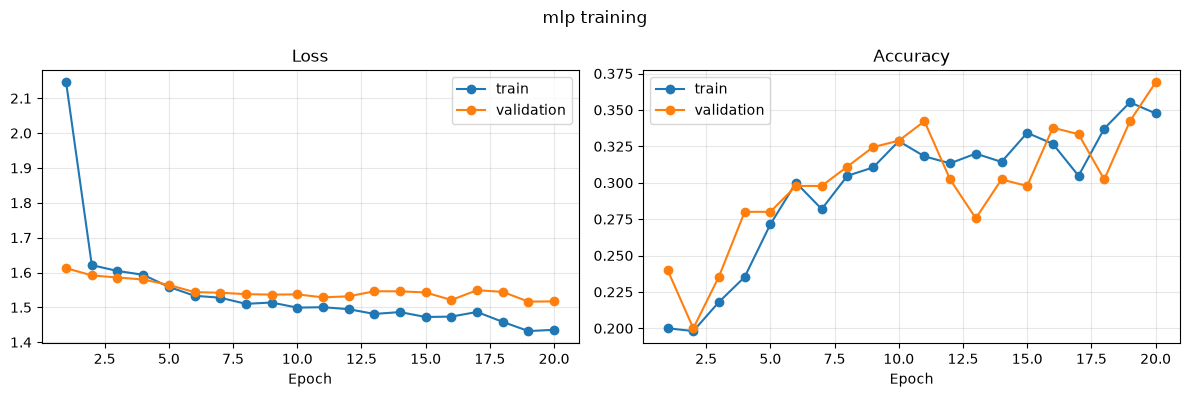

In [91]:
dense_optimizer = torch.optim.Adam(dense_model.parameters(), lr=1e-3, weight_decay=1e-4)
dense_model, dense_history = fit_model(
    dense_model, train_loader, val_loader, dense_optimizer,
    epochs=20, model_path=OUTPUT_DIR / "mlp_best.pt"
)
plot_history(dense_history, "mlp training", "mlp_training_curves.png")

### m2 diagnosis: interpret the curves

- **Underfitting:** training and validation accuracy are both low; both losses remain high.
- **Overfitting:** training loss keeps falling / training accuracy rises, while validation loss rises or validation accuracy stalls.
- **Potential data/split issue:** suspiciously high validation accuracy can mean near-duplicate images, leakage, or a very small/easy validation set.
- **Class confusion:** use the confusion matrix and misclassified examples below to identify the most difficult styles.

mlp test accuracy: 0.3867
               precision    recall  f1-score   support

      Baroque       0.52      0.53      0.53        45
       Cubism       0.67      0.04      0.08        45
Impressionism       0.27      0.07      0.11        45
      Pop_Art       0.46      0.38      0.41        45
      Ukiyo_e       0.32      0.91      0.47        45

     accuracy                           0.39       225
    macro avg       0.45      0.39      0.32       225
 weighted avg       0.45      0.39      0.32       225



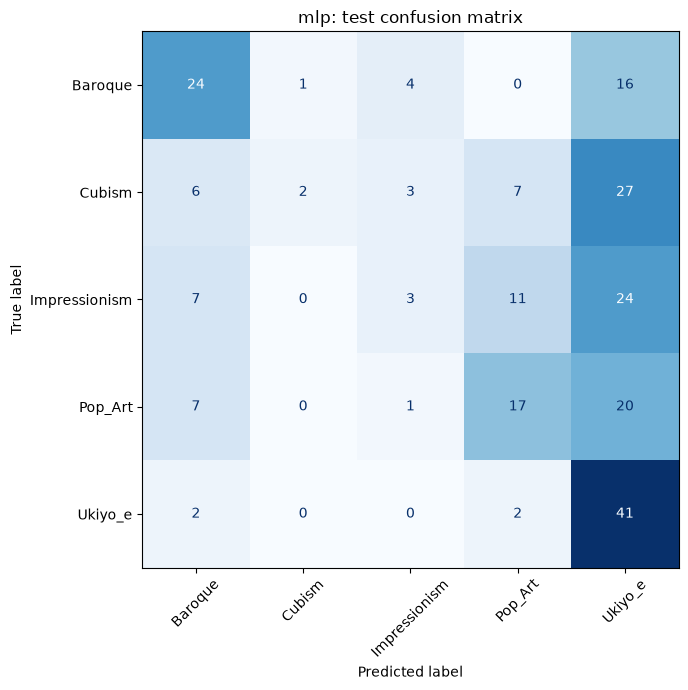

In [96]:
dense_test_acc, y_true_dense, y_pred_dense = evaluate_classifier(dense_model, test_loader, "mlp")